# Topik Modeling dan Klasifikasi Sentimen Pada Pemberitaan Karhutla

## 1. Latar Belakang

Asap tidak mempunyai KTP dan Passpor, sehingga asap itupun tidak mengenal batas administrasi maupun negara. Saat kemarau, kabut asap dari Indonesia ikut menyelimuti negara tetangga di ASEAN, dan media ramai memberitakannya. Liputannya luas melingkupi pemadaman, kesehatan warga, kualitas udara, tanggung jawab perusahaan, sampai dampak lintas negara. Publikasi BKPK Kementerian Kesehatan, *Karhutla di Indonesia: Saat Asap Datang, Kita Siap*, memberi konteks dari sisi kesehatan. Di sisi lain yaitu media sosial, sawit sering dikaitkan dengan karhutla. Hal ini memunculkan pertanyaan: bagaimana artikel berita menyebut sawit saat memberitakan karhutla?

### Pertanyaan Analisis

1. Topik apa yang paling banyak muncul dalam kumpulan pemberitaan karhutla?
2. Bagaimana komposisi sentimen negatif, netral, dan positif pada setiap topik?
3. Dalam konteks apa sawit disebut dalam pemberitaan karhutla, dan pada topik mana penyebutannya paling banyak?

## 2. Metode dan Alur Analisis

**Data hasil scrapping media → cleansing data dan transformasi → pemilihan kategori core=berhubungan 'karhutla' → pelabelan berbasis rule → ekspor data yang berlabel → TF-IDF dan NMF → jumlah artikel per topik → komposisi sentimen per topik.**

NMF dipilih sebagai model yang digunakan untuk pembuatan model topik. Pembobotan dengan TF-IDF digunakan untuk menonjolkan istilah pembeda antardokumen, kemudian NMF mengelompokkan pola istilah tersebut.

## 3. Analisis Utama

### 3.1. Sumber dan Kesiapan Data

#### Sumber Data

Data source awal memuat **14.004 baris artikel bertanggal 1 April–22 Oktober 2026** dalam `data/karhutla-apr-oct2026.jsonl`. Pengambilan data menggunakan solusi di github untuk media scrapper yaitu [news-watch](https://github.com/okkymabruri/news-watch). Setiap baris data berisi judul, tanggal terbit, media, isi, dan tautan artikel. Selanjutnya, data tersebut diolah, dan hasilnya disimpan dalam `data/karhutla_cleansing.csv`dengan jumlah **9.161 artikel bersih**, termasuk **5.865 artikel kategori `core`**.

**Alur data:** JSONL mentah → pembersihan dan penyaringan → CSV bersih → pemilihan kategori `core='karhutla'` → pelabelan sentimen → pemodelan NMF → komposisi sentimen per topik.

#### Pengolahan Data Sebelum Pemodelan

Tahapan pengolahan yang sudah dilakukan pada tahapan sebelumnya adalah:
1. Penyeragaman metadata media, penulis, kategori, judul, dan tanggal terbit.
2. Pembersihan HTML, iklan, tautan, bagian “Baca juga”, kredit penulis, dan spasi tanpa menerjemahkan isi artikel.
3. Penentuan kategori `core`, `generic_fire`, atau `off_topic` berdasarkan istilah pada judul dan isi, serta perkiraan bahasa teks nya.
4. Pencocokan nama daerah dengan kamus lokasi.
5. Penyaringan duplikat berdasarkan URL, isi, dan judul setelah normalisasi. 
6. Pemeriksaan identitas, URL, judul, isi, tanggal, dan kelengkapan teks.

In [1]:
#load data dan ekplorasi data
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import NMF

RANDOM_STATE = 42
file_data = Path('data') / 'karhutla_cleansing.csv'

data = pd.read_csv(file_data, parse_dates=['publish_date'], keep_default_na=False)
kolom_wajib = {
    'doc_id', 'title_clean', 'content_clean', 'publish_date', 'relevance_tier',
    'link', 'link_normalized', 'title_hash', 'content_hash',
    'source_domain', 'geo_name',
}
assert kolom_wajib.issubset(data.columns), 'Kolom CSV belum lengkap; periksa hasil pengolahan data.'
assert len(data) > 0, 'CSV sumber kosong.'
assert data['doc_id'].is_unique, 'Identitas artikel berulang.'
assert data['publish_date'].notna().all(), 'Tanggal terbit tidak valid.'
assert (
    data['publish_date'].between('2026-04-01', '2026-11-01', inclusive='left').all()
), 'Tanggal di luar periode April–Oktober 2026.'
assert data['content_clean'].str.strip().ne('').all(), 'Isi artikel kosong.'

for kolom in ['link_normalized', 'title_hash', 'content_hash']:
    nilai = data[kolom]
    nilai_terisi = nilai[nilai != '']
    assert not nilai_terisi.duplicated().any(), f'Duplikat artikel pada {kolom}.'
    
data.head()

,doc_id,title,title_clean,publish_date,date,year,month,month_label,week,day_name,...,title_hash,dup_content_n,dup_title_n,is_dup_content,is_dup_title,is_duplicate,link_normalized,dup_link_n,is_dup_link,duplicate_of
0,D00001,Kronologi Truk Pengangkut LPG Terbakar di Tol ...,Kronologi Truk Pengangkut LPG Terbakar di Tol ...,2026-05-05 17:09:00,2026-05-05,2026,5,2026-05,19,Selasa,...,8ee2acdd63be6c4be9da5eb20860ec25,1,1,False,False,False,grid.id/read/044376795/kronologi-truk-pengangk...,1,False,
1,D00002,"Rumah Hangus Terbakar, Begini Cara Anisa Rahma...","Rumah Hangus Terbakar, Begini Cara Anisa Rahma...",2026-06-13 14:29:00,2026-06-13,2026,6,2026-06,24,Sabtu,...,e36e785a5441334c48e0f89b813c67be,1,1,False,False,False,grid.id/read/044387428/rumah-hangus-terbakar-b...,1,False,
2,D00003,Kronologi Pria di Ciputat Terbakar Saat Hendak...,Kronologi Pria di Ciputat Terbakar Saat Hendak...,2026-05-31 08:05:00,2026-05-31,2026,5,2026-05,22,Minggu,...,cd008ec809aa388749ccbc3c12e213fb,1,1,False,False,False,grid.id/read/044383688/kronologi-pria-di-ciput...,1,False,
3,D00004,Lapak Toko di Jalan Usman Sadar Gresik Terbaka...,Lapak Toko di Jalan Usman Sadar Gresik Terbaka...,2026-06-21 17:56:55,2026-06-21,2026,6,2026-06,25,Minggu,...,ba753c2a8ab86a6ac7101dc8d0bb7c0b,1,1,False,False,False,beritajatim.com/lapak-toko-di-jalan-usman-sada...,1,False,
4,D00005,Motor Remaja Asal Tuban Terbakar Setelah Kecel...,Motor Remaja Asal Tuban Terbakar Setelah Kecel...,2026-06-01 21:08:18,2026-06-01,2026,6,2026-06,23,Senin,...,8d2efc52911f481ed4111f13fc3462b5,1,1,False,False,False,beritajatim.com/motor-remaja-asal-tuban-terbak...,1,False,


In [2]:
data.describe()

,publish_date,year,month,week,hour,n_chars_raw,n_chars,n_words,core_hits,fire_hits,n_provinces,geo_score,dup_content_n,dup_title_n,dup_link_n
count,9161,9161.0,9161.000000,9161.000000,9161.000000,9161.000000,9161.000000,9161.000000,9161.000000,9161.000000,9161.000000,9161.000000,9161.000000,9161.000000,9161.000000
mean,2026-09-23 18:07:53.997598720,2026.0,9.242222,38.945857,13.745333,3495.617836,3166.566423,423.796310,5.833643,5.126078,2.100207,1.850344,1.423316,1.478660,1.475385
min,2026-04-01 09:30:37,2026.0,4.000000,14.000000,0.000000,222.000000,203.000000,28.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,1.000000
25%,2026-09-03 20:37:11,2026.0,9.000000,36.000000,10.000000,2132.000000,1958.000000,265.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
50%,2026-10-10 10:10:00,2026.0,10.000000,41.000000,14.000000,2853.000000,2641.000000,355.000000,5.000000,3.000000,1.000000,1.000000,1.000000,1.000000,1.000000
75%,2026-10-18 16:04:00,2026.0,10.000000,42.000000,18.000000,3949.000000,3687.000000,490.000000,9.000000,8.000000,2.000000,4.000000,2.000000,2.000000,2.000000
max,2026-10-22 23:57:04,2026.0,10.000000,43.000000,23.000000,160350.000000,30502.000000,4563.000000,77.000000,94.000000,34.000000,12.000000,10.000000,10.000000,10.000000
std,NaN,0.0,1.149497,5.082584,5.697667,3190.199047,2183.254929,294.801401,6.696822,6.245115,2.849117,1.534459,0.802859,0.812302,0.810055


Ringkasan statistik diatas mencakup metadata artikel, termasuk tanggal dan panjang teks. Data awal mencakup 9.161 artikel dan memastikan tidak ada identitas berulang, tanggal di luar periode, atau isi kosong. Adapun sebaran tanggal menggambarkan periode pemberitaan dalam data yang tersedia yaitu dari 1 April 2026 s/d 22 Oktober 2026.

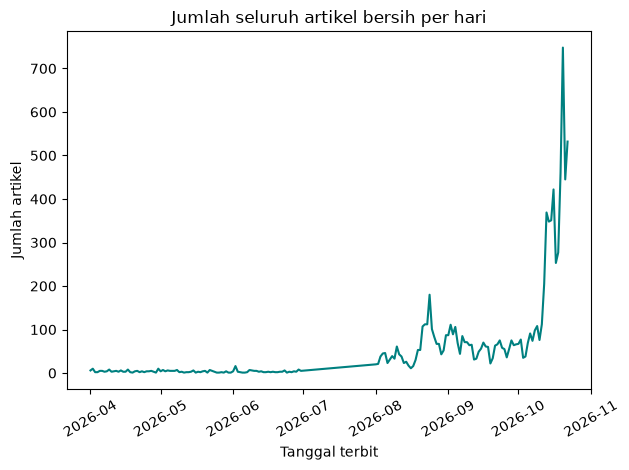

Tanggal dengan artikel terbanyak: 2026-10-20
Jumlah artikel pada tanggal tersebut: 748


In [3]:
#visualisasi tren berita media berdasarkan harian
jumlah_harian = data.groupby(data['publish_date'].dt.date).size()
fig, ax = plt.subplots()
ax.plot(jumlah_harian.index, jumlah_harian.values, color='teal')
ax.set(
    xlabel='Tanggal terbit',
    ylabel='Jumlah artikel',
    title='Jumlah seluruh artikel bersih per hari',
)
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()
print('Tanggal dengan artikel terbanyak:', jumlah_harian.idxmax())
print('Jumlah artikel pada tanggal tersebut:', jumlah_harian.max())

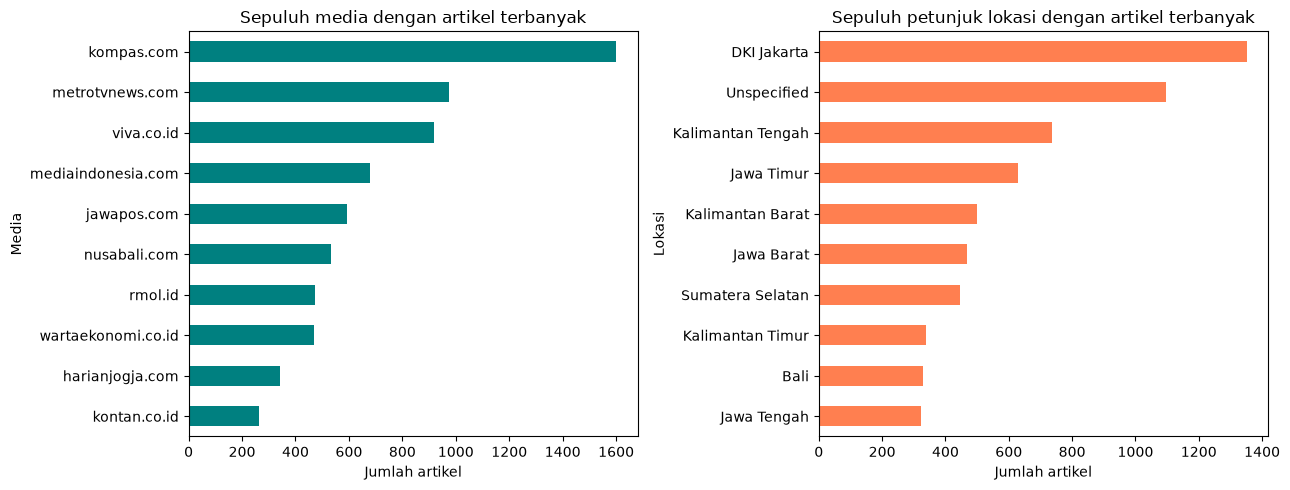

In [4]:
#visualisasi berita berdasarkan media dan lokasi nya
media_terbanyak = data['source_domain'].value_counts().head(10)
lokasi_terbanyak = data['geo_name'].value_counts().head(10)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
media_terbanyak.sort_values().plot.barh(ax=axes[0], color='teal')
lokasi_terbanyak.sort_values().plot.barh(ax=axes[1], color='coral')
axes[0].set(title='Sepuluh media dengan artikel terbanyak', xlabel='Jumlah artikel', ylabel='Media')
axes[1].set(
    title='Sepuluh petunjuk lokasi dengan artikel terbanyak',
    xlabel='Jumlah artikel',
    ylabel='Lokasi',
)
plt.tight_layout()
plt.show()

Grafik line-chart diatas menunjukan jumlah berita harian tertinggi sebanyak **748 artikel pada 20 Oktober 2026**. Media dengan artikel terbanyak adalah **kompas.com (1.601 artikel)**, **metrotvnews.com (973 artikel)**, dan **viva.co.id (919 artikel)**.

#### Pemeriksaan Kategori Relevansi

Tabel berikut menampilkan `doc_id`, `title_clean`, dan `relevance_tier` untuk memeriksa identitas, judul, dan kategori artikel. Ringkasan `describe()` sebelumnya hanya merangkum kolom numerik secara bawaan.

| Kategori | Aturan Pengelompokan |
| :--- | :--- |
| `core` | Cocok dengan istilah terkait karhutla, seperti kebakaran hutan, kabut asap, atau lahan gambut |
| `generic_fire` | Memuat istilah kebakaran umum tanpa kecocokan dengan istilah karhutla |
| `off_topic` | Tidak memenuhi kedua aturan tersebut |


In [5]:
#contoh data
kolom_pilihan = ['doc_id', 'title_clean', 'relevance_tier']
display(data[kolom_pilihan].head(10))

,doc_id,title_clean,relevance_tier
0,D00001,Kronologi Truk Pengangkut LPG Terbakar di Tol ...,generic_fire
1,D00002,"Rumah Hangus Terbakar, Begini Cara Anisa Rahma...",generic_fire
2,D00003,Kronologi Pria di Ciputat Terbakar Saat Hendak...,generic_fire
3,D00004,Lapak Toko di Jalan Usman Sadar Gresik Terbaka...,generic_fire
4,D00005,Motor Remaja Asal Tuban Terbakar Setelah Kecel...,generic_fire
5,D00008,Kronologi Dua Anak di Sumedang Jadi Korban Pen...,off_topic
6,D00009,Kronologi Wanita di Sumsel Bakar 3 Kendaraan B...,generic_fire
7,D00010,"Kronologi Anak Bakar Rumah Orang Tua di Pati, ...",generic_fire
8,D00011,"Imbas Harga Pertamax Melonjak, Zaskia Adya Mec...",off_topic
9,D00012,Tips Ampuh Mencegah Bau Badan Saat Cuaca Panas,off_topic


In [6]:
#jumlah berita berdasarkan kategori
jumlah_kategori = data['relevance_tier'].value_counts()
display(jumlah_kategori)

nama_kategori = {
    'core': 'Karhutla',
    'generic_fire': 'Kebakaran umum',
    'off_topic': 'Di luar topik',
}
komposisi = jumlah_kategori.rename(index=nama_kategori)
display(komposisi)

relevance_tier
core            5865
off_topic       1805
generic_fire    1491
Name: count, dtype: int64

relevance_tier
Karhutla          5865
Di luar topik     1805
Kebakaran umum    1491
Name: count, dtype: int64

Hasil pengelompokan mencakup 5.865 artikel core, 1.491 artikel kebakaran umum dan 1.805 artikel di luar topik.

In [7]:
#berita dengan kategori core
kondisi_karhutla = data['relevance_tier'] == 'core'
berita = data[kondisi_karhutla].copy()
berita = berita.reset_index(drop=True)

print('Seluruh artikel bersih:', len(data))
print('Artikel kategori core:', len(berita))
display(berita[kolom_pilihan].head())

Seluruh artikel bersih: 9161
Artikel kategori core: 5865


,doc_id,title_clean,relevance_tier
0,D00031,"Kebakaran Pabrik Sandal di Tangerang, BPBD Ant...",core
1,D00128,"Gudang Pendingin Los Angeles Terbakar 5 Hari, ...",core
2,D00138,"BMKG Prediksi Kemarau 2026 Lebih Kering, Ingat...",core
3,D00140,"DPR Minta Kemenhut Siaga Karhutla, Ingatkan Ti...",core
4,D00150,RSUD Dr. Soetomo Pastikan Pasien Meninggal Buk...,core


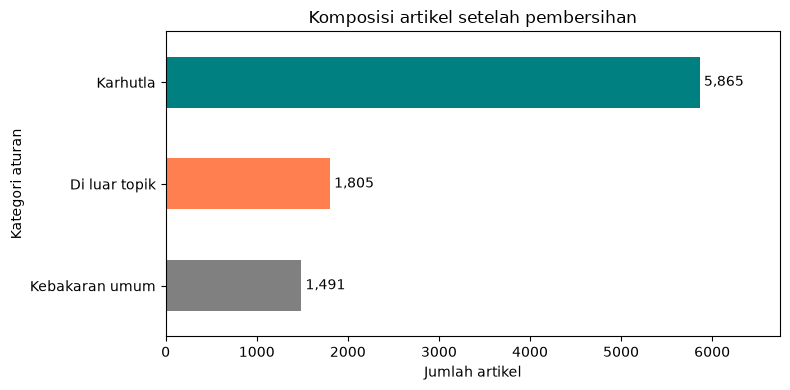

In [8]:
#visualisasi berita berdasarkan kategorinya
fig, ax = plt.subplots(figsize=(8, 4))
komposisi.plot.barh(ax=ax, color=['teal', 'coral', 'gray'])
ax.invert_yaxis()
ax.set(
    title='Komposisi artikel setelah pembersihan',
    xlabel='Jumlah artikel',
    ylabel='Kategori aturan',
)
for posisi, jumlah in enumerate(komposisi):
    ax.text(jumlah, posisi, f' {jumlah:,}', va='center')
ax.margins(x=0.15)
plt.tight_layout()
plt.show()

Sebanyak **5.865 dari 9.161 artikel bersih (64,0%)** dikategorikan sebagai `core`,  diikuti 1.805 sebagai `off_topic`, dan 1.491 sebagai `generic_fire`

### 3.2. Pelabelan Sentimen

Pelabelan menggunakan bantuan AI dengan rule berurutan sebagai berikut:

| Label | Makna dalam Aturan |
| :--- | :--- |
| `negatif` | Dampak buruk, ancaman meningkat, kritik, atau kebakaran belum teratasi |
| `positif` | Keadaan membaik, manfaat pencegahan, atau tindakan penanganan tertentu |
| `netral` | Informasi umum, rencana atau hasil belum pasti, atau artikel di luar konteks karhutla Indonesia |

**Alur pelabelan**

1. Artikel di luar konteks karhutla Indonesia → `netral`.
2. Judul diperiksa secara berurutan: penyangkalan, kebakaran belum teratasi, rencana tindakan, dampak berat, kritik, perbaikan, ancaman, penanganan. Jika ada yang cocok → label sesuai aturan tersebut.
3. Jika judul belum dapat menentukan, pola dihitung pada kalimat isi konten yang memuat istilah karhutla. Jika tidak ada kalimat itu, pakai 1.600 karakter awal isi.
4. Menentukan label dari jumlah pola:
   - `negatif`: minimal tiga pola negatif dan lebih dari 1,5 kali pola positif.
   - `positif`: syarat sebaliknya.
   - Selain itu → `netral`.


In [9]:
import re


def buat_pola(teks_pola):
    return re.compile(teks_pola, re.IGNORECASE)


pola_topik_utama = buat_pola(
    r'\bkarhutla\b|kebakaran\s+(?:hutan|lahan|gambut|savana|gunung|bukit)|'
    r'(?:hutan|lahan|gambut|savana)\s+(?:\w+\s+){0,4}(?:terbakar|kebakaran)|'
    r'pembakaran\s+(?:hutan|lahan)|kabut\s+asap|kebakaran\s+(?:tn\b|'
    r'taman\s+nasional)|asap\s+karhutla'
)

pola_topik_pendukung = buat_pola(
    r'\bgambut\b|\btitik\s+(?:api|panas)\b|\bhotspot\b|asap\s+(?:kiriman|'
    r'kebakaran)|\b(?:kebakaran|pemadaman|terbakar)\b'
)

pola_luar_negeri = buat_pola(
    r'\b(?:los angeles|california|amerika|prancis|spanyol|portugal|kanada|'
    r'australia|chili|chile|yunani|turki|turkiye|jepang|korea|rusia|siberia|'
    r'italia|israel|iran|selat hormuz|china|tiongkok|dinosaurus|asteroid)\b|'
    r'\bmalaysia\b|\bsingapura\b|\bthailand\b|\bbrasil\b|\bbrunei\b|\bindia\b'
)

pola_indonesia = buat_pola(
    r'\b(?:indonesia|karhutla|sumat[er]+a|kalimantan|riau|jambi|sumsel|sumut|'
    r'sumbar|kalteng|kaltim|kalbar|kalsel|aceh|papua|sulawesi|sulsel|sultra|'
    r'bnpb|kemenhut|bmkg|prabowo|jokowi|ri)\b|\btni\b|\bpolri\b|\bmenhut\b|'
    r'\bperhutani\b'
)

pola_kebakaran_langsung = buat_pola(
    r'karhutla|kebakaran\s+(?:hutan|lahan|gambut|savana|gunung|bukit)|'
    r'pembakaran\s+(?:hutan|lahan)|(?:hutan|lahan|gambut|'
    r'savana)\s+(?:\w+\s+){0,4}terbakar|kabut\s+asap|asap\s+karhutla|'
    r'\btitik\s+(?:api|panas)\b|\bhotspot\b'
)

#### Pola Dampak, Penanganan, dan Pengecualian

- Pola sentimen membedakan dampak buruk, perbaikan, rencana, kritik, ancaman, dan penyangkalan.
- Pola tambahan menangani frasa seperti “belum padam”, “akan dipadamkan”, serta penyangkalan hubungan dengan asap. 
- Kata “padam” tidak langsung berarti keberhasilan jika muncul dalam frasa pengecualian.

In [10]:
pola_negatif = buat_pola(
    r'tewas|meninggal|kematian|korban\s+jiwa|luka(?:\s+bakar)?|\bispa\b|sesak|'
    r'ters(?:erang|erang)|sakit|tidak\s+sehat|berbahaya|bahaya|darurat|ancam|'
    r'risiko|rawan|waspada|waswas|khawatir|cemas|lonjak|meningkat|'
    r'makin\s+(?:tinggi|parah|pekat|luas)|meluas|memburuk|parah|pekat|kepung|'
    r'selimuti|tercemar|polusi|krisis|kekeringan|lebih\s+kering|kerugian|'
    r'kerusakan|rusak|hangus|ludes|terbakar|kebakaran\s+(?:kembali|berulang)|'
    r'terbakar\s+lagi|kembali\s+(?:melanda|terjadi)|belum\s+(?:padam|aman|'
    r'mereda|teratasi)|sulit|terkendala|hambat|terganggu|ganggu|tertunda|'
    r'ditunda|dibatalkan|tutup|ditutup|diliburkan|daring|terputus|anjlok|gagal|'
    r'lemah|minim|kritik|dikritik|sentil|tak\s+serius|tidak\s+serius|abaikan|'
    r'abai|belum\s+efektif|kurang\s+(?:efektif|optimal)|tampar|protes|geruduk|'
    r'terpapar|mengungsi|pengungsi|penderita|berbulan|sepekan|marak|kesulitan|'
    r'keresahan|bencana|kebakaran\s+hutan.*(?:\d[\d.,]*\s*(?:ha\b|hektar))|'
    r'batuk|paru|dampak\s+kesehatan|diliburkan|belum\s+reda|terlibat|terdampak|'
    r'menggila'
)

pola_positif = buat_pola(
    r'berhasil|sukses|sudah\s+padam|telah\s+padam|berhasil\s+dipadamkan|'
    r'\bdipadamkan\b|\bpadamkan\b|\bpadam\b|\bteratasi\b|\bterkendali\b|'
    r'\bmembaik\b|\bmereda\b|\bpulih\b|pemulihan|direhabilitasi|dilepasliarkan|'
    r'menurun|berkurang|penurunan|turun\s+dari|turun\s+\d|tekan\s+(?:angka|'
    r'jumlah|risiko|karhutla)|tanpa\s+(?:api|bakar)|bebas\s+(?:api|asap)|'
    r'cegah\s+karhutla|pencegahan|pembasahan|rewetting|restorasi|sekat\s+kanal|'
    r'deteksi\s+dini|inovasi|tingkatkan\s+kesiapsiagaan|perkuat\s+(?:pencegahan|'
    r'pengendalian)|bantuan|layanan\s+kesehatan\s+gratis|galang|donasi|salurkan|'
    r'disalurkan|bagikan\s+masker|dibagikan|tangkap\s+pelaku|ditangkap|'
    r'tahan\s+\d+\s+tersangka|tersangka|sanksi|bekukan|penegakan\s+hukum|'
    r'terjunkan|dikerahkan|kerahkan|optimalkan|diterapkan|terapkan|dilengkapi|'
    r'investasi\s+untuk\s+kesehatan|bagi(?:kan)?\s+masker|\bbanpres\b|'
    r'rumah\s+oksigen|\bbantu(?:an)?\b|pasukan\s+darat\s+dipertebal|'
    r'sekat\s+bakar'
)

pola_dampak_berat = buat_pola(
    r'tewas|meninggal|kematian|korban\s+jiwa|terluka|luka\s+bakar|ters(?:erang|'
    r'erang)\s+ispa|ispa.*(?:melonjak|meningkat)|'
    r'(?:\d[\d.,]*\s+(?:ribu\s+)?(?:warga|orang|anak|bayi)).*(?:ispa|sakit)|'
    r'kualitas\s+udara.*(?:memburuk|bahaya|tidak\s+sehat)|(?:rusak|'
    r'hilang).*habitat|hilangkan\s+ruang\s+hidup|kerugian|gagal|belum\s+padam|'
    r'belum\s+aman|kembali\s+(?:melanda|terbakar)|terbakar\s+lagi|'
    r'pemadaman.*(?:hambat|sulit|krisis)|(?:sulit|hambat).*pemadaman|gugur|'
    r'duka\s+mendalam|korupsi|penyelewengan'
)

pola_perbaikan = buat_pola(
    r'berhasil\s+(?:di)?(?:padam|kendali|atasi|cegah)|(?:sudah|'
    r'telah)\s+(?:berhasil\s+)?(?:padam|dipadamkan|terkendali)|\bdipadamkan\b|'
    r'\bpadamkan\b|\bpadam\b|\bmereda\b|\bmembaik\b|menurun|berkurang|'
    r'turun\s+dari|turun\s+\d|penurunan|\bpulih\b|dilepasliarkan|direhabilitasi|'
    r'(?:karhutla|hotspot|titik\s+(?:panas|api)|kasus\s+ispa|'
    r'tren\s+karhutla).{0,65}\bturun\b|\bzero\s+karhutla\b|nihil\s+(?:karhutla|'
    r'titik\s+api|titik\s+panas)'
)

pola_rencana = buat_pola(
    r'\b(?:akan|rencana|direncanakan|wacana|janji|berjanji|usul|usulkan|minta|'
    r'diminta|desak|dorong|didorong|siapkan|disiapkan|kaji|rapat|bahas|imbau|'
    r'imbauan|tips|cara|website|apa\s+itu|mengenal|sejarah|pengertian)\b|'
    r'sayembara|syembara|tunggu\s+persetujuan'
)

pola_kritik = buat_pola(
    r'dikritik|kritik|gagal|lemah|minim|sentil|tak\s+serius|tidak\s+serius|'
    r'belum\s+aman|belum\s+efektif|tak\s+kunjung|belum\s+mereda|'
    r'kurang\s+optimal|belum\s+optimal|sulit\s+(?:di)?padam|belum\s+(?:reda|'
    r'tuntas|terkendali|teratasi)|tidak\s+kunjung|tak\s+bisa\s+dipadam|'
    r'perlu\s+dipadamkan|masih\s+(?:paling\s+luas|membara|berkobar)|tak\s+cukup|'
    r'tidak\s+cukup|tak\s+empati|tidak\s+empati|melanggar\s+hukum|pelanggaran|'
    r'markup|mark\s+up'
)

pola_ancaman = buat_pola(
    r'ancam|risiko|rawan|waspada|waswas|khawatir|lonjak|meningkat|makin|meluas|'
    r'memburuk|pekat|kepung|selimuti|tercemar|krisis|kekeringan|lebih\s+kering|'
    r'terdeteksi|deteksi.*titik|\d[\d.,]*\s+titik\s+(?:api|panas)|hotspot|'
    r'terbakar|ganggu|tertunda|tutup|terputus|anjlok|terpapar|berbulan|sepekan|'
    r'marak|diliburkan|pjj\b|\bpenderita\b|\bbatuk\b|\bispa\b|'
    r'pangkas\s+penerbangan|berpotensi\s+terdampak|belum\s+reda|menggila|'
    r'bencana|terlibat|\d[\d.,]*\s*(?:ribu\s+)?(?:ha\b|hektare?\b|hektar\b)|'
    r'\d+\s+(?:karhutla|kebakaran)|permintaan\s+(?:tabung\s+)?oksigen\s+meningka'
    r't'
)

pola_penyangkalan = buat_pola(
    r'(?:tidak|tak|tanpa|nihil|belum\s+ada)\s+(?:ada\s+)?(?:laporan\s+)?korban(?'
    r':\s+jiwa|\s+luka)?|(?:tidak|tak)\s+(?:lagi\s+)?(?:terbakar|berbahaya|'
    r'terganggu)|bukan\s+(?:karena|akibat)\s+asap'
)

#### Pola Konteks pada Judul

Daftar berikut memuat pengecualian yang digunakan dalam pemeriksaan judul dan relevansi. Pola dipisahkan dari fungsi pelabelan supaya aturan mudah diperiksa satu per satu.

In [11]:
pola_negara_tetangga = buat_pola(
    r'malaysia|singapura|brunei|thailand'
)

pola_asap_lintas_batas = buat_pola(
    r'(?:karhutla|kebakaran).{0,80}(?:indonesia|sumat[er]+a|kalimantan)|'
    r'(?:indonesia|sumat[er]+a|kalimantan).{0,80}(?:karhutla|kebakaran)'
)

pola_topik_lain = buat_pola(
    r'kecelakaan|helikopter.*jatuh|pabrik|gudang|rumah\s+sakit|rsud|pertamax|'
    r'bau\s+badan|sepak\s+bola'
)

pola_hutan_dan_lahan = buat_pola(
    r'gambut|\blahan\b|\bhutan\b'
)

pola_api_dan_pemadaman = buat_pola(
    r'titik\s+(?:api|panas)|hotspot|padam|kebakaran|terbakar'
)

pola_bantahan_sebab = buat_pola(
    r'bukan\s+(?:asap\s+)?karhutla|bukan\s+(?:karena|akibat)\s+(?:asap|'
    r'karhutla)|bantah.*meninggal.*(?:asap|karhutla)'
)

pola_belum_teratasi = buat_pola(
    r'belum\s+(?:reda|tuntas|terkendali|teratasi)|sulit\s+(?:di)?padam|'
    r'perlu\s+dipadamkan|(?:baru|hanya)\s+(?:\w+\s+){0,3}padam.*(?:kembali|lagi)'
)

pola_hasil_belum_pasti = buat_pola(
    r'akan\s+dipadamkan|untuk\s+dipadamkan|agar\s+padam|siap\s+bantu|'
    r'tawaran\s+bantuan|uji\s+coba|bagaimana\s+hasilnya|benarkah|jika\s+berhasil'
)

pola_eskalasi = buat_pola(
    r'meluas|melonjak|memburuk'
)

pola_pengecualian_perbaikan = buat_pola(
    r'tewas|meninggal|kematian|terluka|luka\s+bakar|belum\s+padam|belum\s+aman|'
    r'gagal'
)

pola_penghalang_perbaikan = buat_pola(
    r'belum|bukan|tak\s+kunjung|gagal|terancam'
)

pola_pencegahan = buat_pola(
    r'(?:antisipasi|agar|supaya|hindari|mencegah|'
    r'cegah)\s+(?:\w+\s+){0,4}(?:risiko|ancaman|meluas|kebakaran|hotspot)|'
    r'pemetaan\s+hotspot'
)

pola_pengecualian_pencegahan = buat_pola(
    r'ancaman.*langkah|makin\s+luas|melonjak|memburuk|terbakar|belum|meningkat|'
    r'diliburkan'
)

#### Fungsi Pelabelan

Fungsi pelabelan yang dilakukan untuk menentukan keterkaitan dengan karhutla Indonesia, dan menerapkan aturan sesuai urutan pemeriksaan.

In [12]:
def rapikan_teks(teks):
    return re.sub(r'\s+', ' ', teks or '').strip().lower()

def siapkan_isi(artikel):
    teks = artikel.get('content_clean') or artikel.get('content') or ''
    teks = re.split(r'\*{3,}', teks, maxsplit=1)[0]
    teks = re.sub(r'(?:baca juga|baca selengkapnya)\s*:[^\n]*(?:\n|$)', ' ', teks, flags=re.I)
    return rapikan_teks(teks)


def beri_label_sentimen(artikel):
    judul = rapikan_teks(artikel.get('title_clean') or artikel.get('title'))
    isi = siapkan_isi(artikel)
    awal_isi = isi[:1600]
    kalimat = re.split(r'(?<=[.!?])\s+|\n+', isi)
    kalimat_topik = [bagian for bagian in kalimat if pola_topik_utama.search(bagian)]
    luar_negeri = pola_luar_negeri.search(judul)
    asap_lintas_batas = (
        pola_negara_tetangga.search(judul) and pola_asap_lintas_batas.search(awal_isi)
    )
    if luar_negeri and not pola_indonesia.search(judul) and not asap_lintas_batas:
        return 'netral', 'outside_indonesia', 0, 0
    if not pola_kebakaran_langsung.search(judul) and pola_topik_lain.search(judul):
        return 'netral', 'outside_karhutla_focus', 0, 0
    fokus_karhutla = bool(pola_topik_utama.search(judul))
    fokus_karhutla = (
        fokus_karhutla
        or bool(
            pola_hutan_dan_lahan.search(judul)
            and pola_api_dan_pemadaman.search(judul)
        )
    )
    if not fokus_karhutla:
        porsi_kalimat_topik = len(kalimat_topik) / max(len(kalimat), 1)
        fokus_karhutla = (
            len(kalimat_topik) >= 2
            and (
                bool(pola_topik_pendukung.search(judul))
                or porsi_kalimat_topik >= 0.12
            )
        )
        fokus_karhutla = (
            fokus_karhutla
            or bool(
                pola_topik_pendukung.search(judul)
                and pola_topik_utama.search(awal_isi)
            )
        )
    if not fokus_karhutla:
        return 'netral', 'outside_karhutla_focus', 0, 0
    judul_diperiksa = pola_penyangkalan.sub(' ', judul)
    teks_relevan = ' '.join(kalimat_topik) if kalimat_topik else awal_isi
    jumlah_negatif = len(pola_negatif.findall(pola_penyangkalan.sub(' ', teks_relevan)))
    jumlah_positif = len(pola_positif.findall(teks_relevan))
    if pola_bantahan_sebab.search(judul):
        return 'netral', 'causal_attribution_denied', jumlah_negatif, jumlah_positif
    if pola_belum_teratasi.search(judul_diperiksa):
        return 'negatif', 'headline_unresolved_fire', jumlah_negatif, jumlah_positif
    if pola_hasil_belum_pasti.search(judul_diperiksa):
        if pola_dampak_berat.search(judul_diperiksa) or pola_eskalasi.search(judul_diperiksa):
            return 'negatif', 'headline_harm', jumlah_negatif, jumlah_positif
        return 'netral', 'proposed_or_unverified_response', jumlah_negatif, jumlah_positif
    if pola_dampak_berat.search(judul_diperiksa):
        if (
            pola_perbaikan.search(judul_diperiksa)
            and not pola_pengecualian_perbaikan.search(judul_diperiksa)
        ):
            return 'positif', 'headline_improvement', jumlah_negatif, jumlah_positif
        return 'negatif', 'headline_harm', jumlah_negatif, jumlah_positif
    if pola_kritik.search(judul_diperiksa):
        return 'negatif', 'headline_criticism', jumlah_negatif, jumlah_positif
    if (
        pola_perbaikan.search(judul_diperiksa)
        and not pola_penghalang_perbaikan.search(judul_diperiksa)
    ):
        return 'positif', 'headline_improvement', jumlah_negatif, jumlah_positif
    if pola_ancaman.search(judul_diperiksa):
        if (
            pola_pencegahan.search(judul_diperiksa)
            and pola_positif.search(judul_diperiksa)
            and not pola_pengecualian_pencegahan.search(judul_diperiksa)
        ):
            if pola_rencana.search(judul_diperiksa):
                return 'netral', 'planned_prevention', jumlah_negatif, jumlah_positif
            return 'positif', 'headline_prevention', jumlah_negatif, jumlah_positif
        return 'negatif', 'headline_threat', jumlah_negatif, jumlah_positif
    if pola_positif.search(judul_diperiksa):
        if pola_rencana.search(judul_diperiksa):
            return 'netral', 'planned_action', jumlah_negatif, jumlah_positif
        return 'positif', 'headline_response', jumlah_negatif, jumlah_positif
    if pola_rencana.search(judul_diperiksa):
        return 'netral', 'informational_or_planned', jumlah_negatif, jumlah_positif
    if jumlah_negatif >= 3 and jumlah_negatif > 1.5 * jumlah_positif:
        return 'negatif', 'body_harm_dominates', jumlah_negatif, jumlah_positif
    if jumlah_positif >= 3 and jumlah_positif > 1.5 * jumlah_negatif:
        return 'positif', 'body_response_dominates', jumlah_negatif, jumlah_positif
    return 'netral', 'balanced_or_factual', jumlah_negatif, jumlah_positif

#### Penerapan pada Artikel Kategori Core

Penerapan label sentimen pada artikel dengan kategori core.

In [13]:
nama_alasan = {
    'outside_karhutla_focus': 'Di luar fokus karhutla',
    'outside_indonesia': 'Di luar konteks Indonesia',
    'headline_threat': 'Ancaman atau dampak pada judul',
    'headline_response': 'Penanganan atau pencegahan pada judul',
    'body_harm_dominates': 'Pola negatif lebih banyak pada isi',
    'headline_harm': 'Dampak berat pada judul',
    'headline_improvement': 'Perbaikan keadaan pada judul',
    'balanced_or_factual': 'Informasi umum atau pola belum menentukan',
    'planned_action': 'Rencana tindakan pada judul',
    'informational_or_planned': 'Penjelasan atau rencana umum',
    'body_response_dominates': 'Pola positif lebih banyak pada isi',
    'proposed_or_unverified_response': 'Hasil penanganan belum pasti',
    'headline_criticism': 'Kritik atau kelemahan pada judul',
    'headline_unresolved_fire': 'Kebakaran belum teratasi',
    'causal_attribution_denied': 'Hubungan dengan asap disangkal',
    'headline_prevention': 'Pencegahan pada judul',
    'planned_prevention': 'Rencana pencegahan pada judul',
}

urutan_sentimen = ['negatif', 'netral', 'positif']
kolom_sebelum_label = berita.columns.tolist()
identitas_sebelum_label = berita['doc_id'].tolist()

hasil_label = []
for artikel in berita.to_dict('records'):
    hasil_label.append(beri_label_sentimen(artikel))

rincian_label = pd.DataFrame(
    hasil_label,
    columns=['sentiment', 'kode_alasan', 'kecocokan_negatif', 'kecocokan_positif'],
    index=berita.index,
)
berita['sentiment'] = rincian_label['sentiment']
rincian_label['doc_id'] = berita['doc_id']
rincian_label['Alasan pelabelan'] = rincian_label['kode_alasan'].map(nama_alasan)
assert rincian_label['Alasan pelabelan'].notna().all(), 'Ada alasan pelabelan tanpa penjelasan.'
assert berita['sentiment'].isin(urutan_sentimen).all(), 'Ada label kosong atau tidak valid.'
assert berita['doc_id'].tolist() == identitas_sebelum_label, 'Urutan artikel berubah.'

contoh_label = berita[['doc_id', 'title_clean', 'sentiment']].head(10).copy()
contoh_label['Alasan pelabelan'] = rincian_label['Alasan pelabelan'].head(10)
with pd.option_context('display.max_colwidth', None):
    display(contoh_label)

jumlah_label = berita['sentiment'].value_counts().reindex(urutan_sentimen, fill_value=0)
ringkasan_label = jumlah_label.to_frame('Jumlah artikel')
ringkasan_label['Persentase (%)'] = (100 * jumlah_label / len(berita)).round(2)
display(ringkasan_label)

,doc_id,title_clean,sentiment,Alasan pelabelan
0,D00031,"Kebakaran Pabrik Sandal di Tangerang, BPBD Antisipasi Dampak Asap bagi Warga",netral,Di luar fokus karhutla
1,D00128,"Gudang Pendingin Los Angeles Terbakar 5 Hari, Picu Status Darurat",netral,Di luar konteks Indonesia
2,D00138,"BMKG Prediksi Kemarau 2026 Lebih Kering, Ingatkan Potensi Lonjakan Titik Panas Karhutla",negatif,Ancaman atau dampak pada judul
3,D00140,"DPR Minta Kemenhut Siaga Karhutla, Ingatkan Titik Panas Mulai Terdeteksi di Riau",negatif,Ancaman atau dampak pada judul
4,D00150,"RSUD Dr. Soetomo Pastikan Pasien Meninggal Bukan Karena Asap Kebakaran, Tapi Sudah Kritis",netral,Di luar fokus karhutla
5,D00156,"Selat Hormuz Jadi Titik Panas, Patokan Tarif Kapal Timur Tengah Terancam Dirombak",netral,Di luar konteks Indonesia
6,D00158,Risiko Transisi Energi Ketika Bersumber dari Ekstraksi Mineral Kritis,netral,Di luar fokus karhutla
7,D00159,"Opini: Pembasahan Gambut Bukan Hanya Masalah Lingkungan, Tapi Investasi untuk Kesehatan Publik",positif,Penanganan atau pencegahan pada judul
8,D00160,"BMKG Ingatkan Lagi soal Kemarau, Karhutla dan Kekeringan",negatif,Ancaman atau dampak pada judul
9,D00165,Menelusuri Karhutla Riau di Hutan Alam dan Gambut Perusahaan,negatif,Pola negatif lebih banyak pada isi


,Jumlah artikel,Persentase (%)
sentiment,,
negatif,2787,47.52
netral,2130,36.32
positif,948,16.16


Hasil pelabelan mencakup **2.787 artikel negatif (47,52%)**, **2.132 artikel netral (36,35%)**, dan **946 artikel positif (16,13%)**. Label negatif mempunyai jumlah paling banyak, meskipun porsinya belum mencapai setengah artikel.

In [14]:
#simpan data hasil cleansing dan klasifikasi ke dalam csv terpisah
file_klasifikasi = file_data.with_name('karhutla_cleansing_classification.csv')
kolom_ekspor = kolom_sebelum_label + ['sentiment']

# Pembacaan sebagai teks mempertahankan format sel CSV sumber saat ekspor.
data_ekspor = pd.read_csv(
    file_data, dtype=str, keep_default_na=False,
)
data_ekspor = data_ekspor[data_ekspor['relevance_tier'] == 'core'].reset_index(drop=True)
assert data_ekspor['doc_id'].tolist() == berita['doc_id'].tolist(), 'Artikel ekspor berbeda.'
data_ekspor['sentiment'] = berita['sentiment'].to_numpy()
data_ekspor = data_ekspor[kolom_ekspor]
data_ekspor.to_csv(file_klasifikasi, index=False, encoding='utf-8-sig')

hasil_ekspor = pd.read_csv(file_klasifikasi, dtype=str, keep_default_na=False)
pd.testing.assert_frame_equal(hasil_ekspor, data_ekspor)
assert hasil_ekspor.columns[-1] == 'sentiment', 'Sentimen bukan kolom terakhir.'
print('CSV hasil pelabelan:', file_klasifikasi)
print('Jumlah artikel tersimpan:', len(hasil_ekspor))

CSV hasil pelabelan: data\karhutla_cleansing_classification.csv
Jumlah artikel tersimpan: 5865


### 3.3. Pemodelan Topik dengan TF-IDF dan NMF

Pemodelan menggunakan isi bersih dari **5.865 artikel kategori core** yang sudah memiliki label sentimen. TF-IDF memberi bobot pada istilah berdasarkan frekuensinya dalam artikel dan kekhasannya terhadap kumpulan artikel.

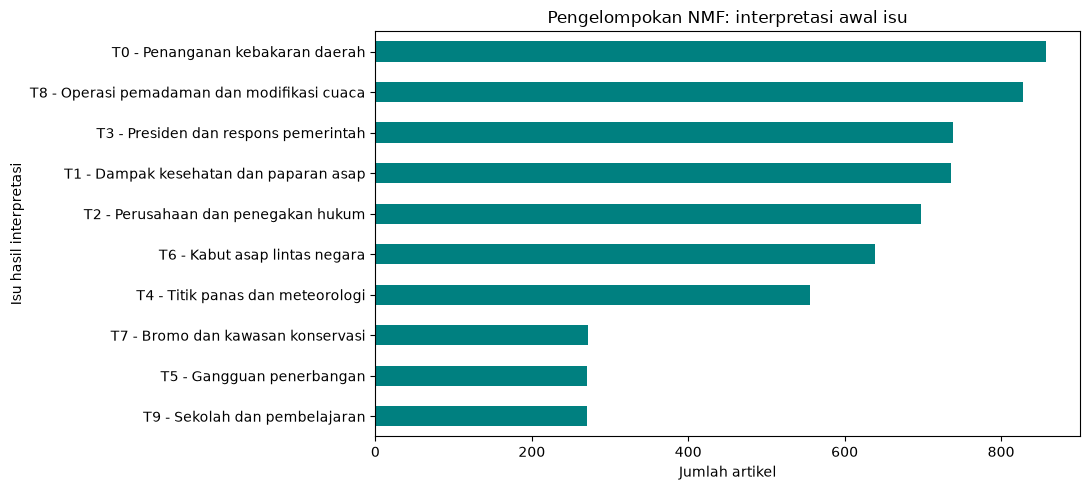

,Isu,Kata pendukung,Contoh judul
0,T0 - Penanganan kebakaran daerah,"api, petugas, lokasi, desa, kawasan, kecamatan...","[Kebakaran Pabrik Sandal di Tangerang, BPBD An..."
1,T1 - Dampak kesehatan dan paparan asap,"kesehatan, pernapasan, ispa, anak, paparan, as...","[Gudang Pendingin Los Angeles Terbakar 5 Hari,..."
2,T2 - Perusahaan dan penegakan hukum,"korporasi, hukum, perusahaan, tersangka, peneg...",[Menelusuri Karhutla Riau di Hutan Alam dan Ga...
3,T3 - Presiden dan respons pemerintah,"prabowo, presiden, dudung, presiden prabowo, s...",[Kronologi Gubernur Kalbar Emosi sampai Bentak...
4,T4 - Titik panas dan meteorologi,"bmkg, panas, titik panas, sebaran, meteorologi...","[BMKG Prediksi Kemarau 2026 Lebih Kering, Inga..."
5,T5 - Gangguan penerbangan,"penerbangan, bandara, jarak pandang, pandang, ...","[2.604 Penerbangan Terdampak Asap Karhutla, As..."
6,T6 - Kabut asap lintas negara,"malaysia, singapura, negara, kabut asap, kabut...","[Selat Hormuz Jadi Titik Panas, Patokan Tarif ..."
7,T7 - Bromo dan kawasan konservasi,"bromo, tnbts, gunung, probolinggo, semeru, ten...",[RSUD Dr. Soetomo Pastikan Pasien Meninggal Bu...
8,T8 - Operasi pemadaman dan modifikasi cuaca,"operasi, kalimantan, bnpb, darat, omc, kaliman...","[Bencana Karhutla Bertambah, BNPB Ungkap Lebih..."
9,T9 - Sekolah dan pembelajaran,"sekolah, pembelajaran, pendidikan, belajar, pj...",[Pemkot Banda Aceh Siapkan Alternatif WFH jika...


Urutan topik berdasarkan jumlah artikel


,Topik,Jumlah artikel,Persentase (%)
Kode topik NMF,,,
0,T0 - Penanganan kebakaran daerah,858,14.63
8,T8 - Operasi pemadaman dan modifikasi cuaca,828,14.12
3,T3 - Presiden dan respons pemerintah,738,12.58
1,T1 - Dampak kesehatan dan paparan asap,736,12.55
2,T2 - Perusahaan dan penegakan hukum,697,11.88
6,T6 - Kabut asap lintas negara,639,10.90
4,T4 - Titik panas dan meteorologi,556,9.48
7,T7 - Bromo dan kawasan konservasi,272,4.64
5,T5 - Gangguan penerbangan,271,4.62


In [15]:
#identifikasi kata umum
kata_umum = sorted(set('''
ada adalah adanya adapun agak agar akan akankah akhir akhiri akhirnya aku
antara antaranya apa apapun apabila apakah apalagi apatah arah artinya asal
atas atau ataukah ataupun awal awalnya bagaimana bagaimanakah bagaimanapun
bagi bagian bahkan bahwa baik bakal banyak bapak baru bawah beberapa begini
begitu belakang belum benar berbagai beri berikan berkata berlaku bermaksud
bermula berpendapat berperan bersamaan bertanya berupa besar betul biasa
bilang bila bilakah bisa bisakah boleh buat bukan bukankah bukanlah bukannya
bulan cara caranya cukup cuma
dahulu dalam dan dapat dari daripada datang dekat demi demikian dengan depan
di dia dianggap diantaranya dibuat dicapai dicatat dilakukan dilihat dimaksud
dimana diminta dipakai dipastikan diri dirinya disampaikan disebut disini
disitu ditambahkan ditanya ditanyakan ditegaskan ditujukan dituturkan diucapkan
diulang diumumkan diutarakan diberi diberikan dijelaskan dikatakan diketahui
dilaporkan dimulai diperlukan disebutkan ditetapkan ditolak ditemukan ditangani
ditangkap dituntut divonis dong dua dulu empat enggak entah gagal gimana
hal hampir hanya hanyalah hari harus haruslah harusnya hingga
ia ialah ikut ingin ini inilah itu itulah
jadi jadinya jangan jarang jelas jelaskan jelasnya jika jikalau juga jumlah
jumlahnya justru
kala kalau kalian kami kamu kan kapan karena karenanya kata katakan keadaan
kecil kedua keduanya keluar kembali kemudian kenapa kepada ketika kini kira
kita lagi lah lain lainnya lalu lama lanjut langsung luas luar
maka makin malah mampu mana masih masing mau maupun melainkan melakukan
melalui melihat memang membuat memerlukan memihak meminta memperoleh mendapat
mendapatkan mengakhiri mengapa mengatakan mengenai menggunakan menghendaki
mengingat menginginkan mengira mengetahui mengucapkan mengulang mengurus
menjelaskan menuju menunjuk menunjukkan menuntut menyatakan menyebut
menyebutkan menyiapkan merupakan meski meskipun minta mirip misal misalkan
misalnya mula mulai mungkin namun nanti nyaris oleh olehnya
pada padahal padanya paling panjang para pasti patut pemerintah perlu pernah
pertama pertanyaan pihak pihaknya pukul pula pun punya rasa rata
saat saja saling sama sambil sampai sampaikan sana sangat satu saya se sebab
sebabnya sebagai sebagaimana sebagainya sebanyak sebelum sebelumnya sebenarnya
seberapa sebuah sebut secara sedang sedangkan sedikit segala segera seharusnya
sehingga sejak sejumlah sekali sekaligus sekarang sekitar selama selanjutnya
seluruh semakin semacam semasa semua semuanya sendiri senang
sepanjang seperti sering serta sesuai setelah setempat setiap sudah supaya
tadi tahu tahun tak tambah tampak tandas tanpa tanya tapi tegas telah tempat
terjadi terhadap termasuk ternyata tertentu tetapi tiap tolong
ucap ujar umum ungkap untuk usai wah waktu walau walaupun
yaitu yakin yakni yang
kompas com detik liputan6 cnbc antara republika tribun sindonews okezone
kumparan tempo katadata mongabay bisnis viva jawapos metrotvnews rmol
wartaekonomi mediaindonesia harianjogja bloombergtechnoz nusabali kontan
suara merdeka pikiran rakyat jpnn inilah idntimes kbr gadis grid
baca juga advertisement gulir lanjut scroll resume content copyright
foto video ilustrasi dokumentasi grafis infografis indeks berita
wib selasa senin rabu kamis jumat sabtu minggu
jakarta indonesia republika co
kata ujar jelas tegas ungkap sebut tambah terang
orang tahun hari bulan kali ke lebih terus
'''.split()))

#setup TF-IDF
tfidf = TfidfVectorizer(
    stop_words=kata_umum,
    min_df=3,
    max_df=0.6,
    ngram_range=(1, 2),
    max_features=20000,
    sublinear_tf=True,
)
matriks = tfidf.fit_transform(berita['content_clean'])
nmf = NMF(n_components=10, init='nndsvda', random_state=RANDOM_STATE, max_iter=400)
bobot_topik = nmf.fit_transform(matriks)
istilah = tfidf.get_feature_names_out()
kata_topik = {}
for nomor, bobot in enumerate(nmf.components_):
    # Urutkan bobot dari terbesar dan ambil delapan istilah teratas.
    urutan_kata = bobot.argsort()[::-1][:8]
    kata_topik[nomor] = istilah[urutan_kata].tolist()

nama_isu = {
    0: 'T0 - Penanganan kebakaran daerah',
    1: 'T1 - Dampak kesehatan dan paparan asap',
    2: 'T2 - Perusahaan dan penegakan hukum',
    3: 'T3 - Presiden dan respons pemerintah',
    4: 'T4 - Titik panas dan meteorologi',
    5: 'T5 - Gangguan penerbangan',
    6: 'T6 - Kabut asap lintas negara',
    7: 'T7 - Bromo dan kawasan konservasi',
    8: 'T8 - Operasi pemadaman dan modifikasi cuaca',
    9: 'T9 - Sekolah dan pembelajaran',
    -1: 'Belum terpetakan',
}
# argmax memilih posisi topik dengan bobot terbesar pada setiap artikel.
berita['topik_nmf'] = bobot_topik.argmax(axis=1)
tanpa_bobot_topik = bobot_topik.sum(axis=1) == 0
berita.loc[tanpa_bobot_topik, 'topik_nmf'] = -1
berita['isu'] = berita['topik_nmf'].map(nama_isu)
ukuran_isu = berita['isu'].value_counts()

fig, ax = plt.subplots(figsize=(11, 5))
ukuran_isu.sort_values().plot.barh(ax=ax, color='teal')
ax.set(
    title='Pengelompokan NMF: interpretasi awal isu',
    xlabel='Jumlah artikel',
    ylabel='Isu hasil interpretasi',
)
plt.tight_layout()
plt.show()

contoh_isu = []
for nomor, kata in kata_topik.items():
    kondisi_topik = berita['topik_nmf'] == nomor
    judul_contoh = berita.loc[kondisi_topik, 'title_clean'].head(2).tolist()
    contoh_isu.append({
        'Isu': nama_isu[nomor],
        'Kata pendukung': ', '.join(kata),
        'Contoh judul': judul_contoh,
    })

contoh_isu = pd.DataFrame(contoh_isu)
display(contoh_isu)

jumlah_artikel_topik = berita['topik_nmf'].value_counts().sort_index()
ringkasan_topik_nmf = pd.DataFrame(index=jumlah_artikel_topik.index)
ringkasan_topik_nmf.index.name = 'Kode topik NMF'
ringkasan_topik_nmf['Topik'] = ringkasan_topik_nmf.index.map(nama_isu)
ringkasan_topik_nmf['Jumlah artikel'] = jumlah_artikel_topik
ringkasan_topik_nmf['Persentase (%)'] = (
    100 * jumlah_artikel_topik / len(berita)
).round(2)
ringkasan_topik_nmf = ringkasan_topik_nmf.sort_values('Jumlah artikel', ascending=False)
assert ringkasan_topik_nmf['Jumlah artikel'].sum() == len(berita)
print('Urutan topik berdasarkan jumlah artikel')
display(ringkasan_topik_nmf)

Topik terbesar adalah **T0 - Penanganan kebakaran daerah (858 artikel; 14,63%)**, diikuti **T8 - Operasi pemadaman dan modifikasi cuaca (828 artikel; 14,12%)** dan **T3 - Presiden dan respons pemerintah (738 artikel; 12,58%)**. Ketiganya mencakup **2.424 artikel atau 41,33%** dari seluruh artikel yang dimodelkan.

Artinya hampir separuh pemberitaan membahas apa yang dilakukan pemerintah, namun bukan penyebab atau dampaknya

### 3.4. Komposisi Sentimen per Topik NMF
Komposisi sentimen dihitung untuk setiap topik NMF. 

In [16]:
kolom_topik_sentimen = ['doc_id', 'topik_nmf', 'isu', 'sentiment']
berita_sentimen = berita[kolom_topik_sentimen].copy()

assert berita_sentimen['doc_id'].is_unique, 'Identitas artikel berulang.'
assert berita_sentimen['sentiment'].isin(urutan_sentimen).all(), 'Ada label tidak valid.'
assert len(berita_sentimen) == len(berita), 'Jumlah artikel berubah.'
print('Jumlah artikel dengan topik NMF dan label sentimen:', len(berita_sentimen))

Jumlah artikel dengan topik NMF dan label sentimen: 5865


In [17]:
#summary jumlah artikel berita per topik dan kompisisi sentimen
jumlah_sentimen_nmf = pd.crosstab(berita_sentimen['topik_nmf'], berita_sentimen['sentiment'])
jumlah_sentimen_nmf = jumlah_sentimen_nmf.reindex(
    columns=urutan_sentimen, fill_value=0,
).sort_index()
jumlah_sentimen_nmf.index.name = 'Topik NMF'
jumlah_sentimen_nmf.columns.name = None

total_per_topik = jumlah_sentimen_nmf.sum(axis=1)
# axis=0 membagi setiap baris dengan total artikel pada topik tersebut.
persen_sentimen_nmf = jumlah_sentimen_nmf.div(total_per_topik, axis=0) * 100
assert total_per_topik.sum() == len(berita_sentimen), 'Total artikel tidak sesuai.'
assert persen_sentimen_nmf.sum(axis=1).round(6).eq(100).all(), 'Persentase tidak sesuai.'

ringkasan_sentimen_nmf = pd.DataFrame(index=jumlah_sentimen_nmf.index)
ringkasan_sentimen_nmf['Isu'] = jumlah_sentimen_nmf.index.map(nama_isu)
assert ringkasan_sentimen_nmf['Isu'].notna().all(), 'Ada topik tanpa nama.'
ringkasan_sentimen_nmf['Total artikel'] = total_per_topik
for sentimen in urutan_sentimen:
    ringkasan_sentimen_nmf[f'Jumlah {sentimen}'] = jumlah_sentimen_nmf[sentimen]
for sentimen in urutan_sentimen:
    ringkasan_sentimen_nmf[f'{sentimen} (%)'] = persen_sentimen_nmf[sentimen].round(2)

sentimen_terbanyak = []
for nomor in jumlah_sentimen_nmf.index:
    jumlah_per_topik = jumlah_sentimen_nmf.loc[nomor]
    nilai_tertinggi = jumlah_per_topik.max()
    label_tertinggi = jumlah_per_topik[jumlah_per_topik == nilai_tertinggi].index
    sentimen_terbanyak.append(' / '.join(label_tertinggi))

ringkasan_sentimen_nmf['Sentimen terbanyak'] = sentimen_terbanyak
ringkasan_sentimen_nmf['Porsi terbesar (%)'] = persen_sentimen_nmf.max(axis=1).round(2)
display(ringkasan_sentimen_nmf)

,Isu,Total artikel,Jumlah negatif,Jumlah netral,Jumlah positif,negatif (%),netral (%),positif (%),Sentimen terbanyak,Porsi terbesar (%)
Topik NMF,,,,,,,,,,
0,T0 - Penanganan kebakaran daerah,858,446,280,132,51.98,32.63,15.38,negatif,51.98
1,T1 - Dampak kesehatan dan paparan asap,736,470,201,65,63.86,27.31,8.83,negatif,63.86
2,T2 - Perusahaan dan penegakan hukum,697,245,249,203,35.15,35.72,29.12,netral,35.72
3,T3 - Presiden dan respons pemerintah,738,205,359,174,27.78,48.64,23.58,netral,48.64
4,T4 - Titik panas dan meteorologi,556,294,228,34,52.88,41.01,6.12,negatif,52.88
5,T5 - Gangguan penerbangan,271,186,70,15,68.63,25.83,5.54,negatif,68.63
6,T6 - Kabut asap lintas negara,639,297,303,39,46.48,47.42,6.10,netral,47.42
7,T7 - Bromo dan kawasan konservasi,272,165,68,39,60.66,25.00,14.34,negatif,60.66
8,T8 - Operasi pemadaman dan modifikasi cuaca,828,304,297,227,36.71,35.87,27.42,negatif,36.71


Seluruh topik tetap mencakup **5.865 artikel**: **2.787 negatif**, **2.132 netral**, dan **946 positif**. 

#### Visualisasi Sentimen per Topik

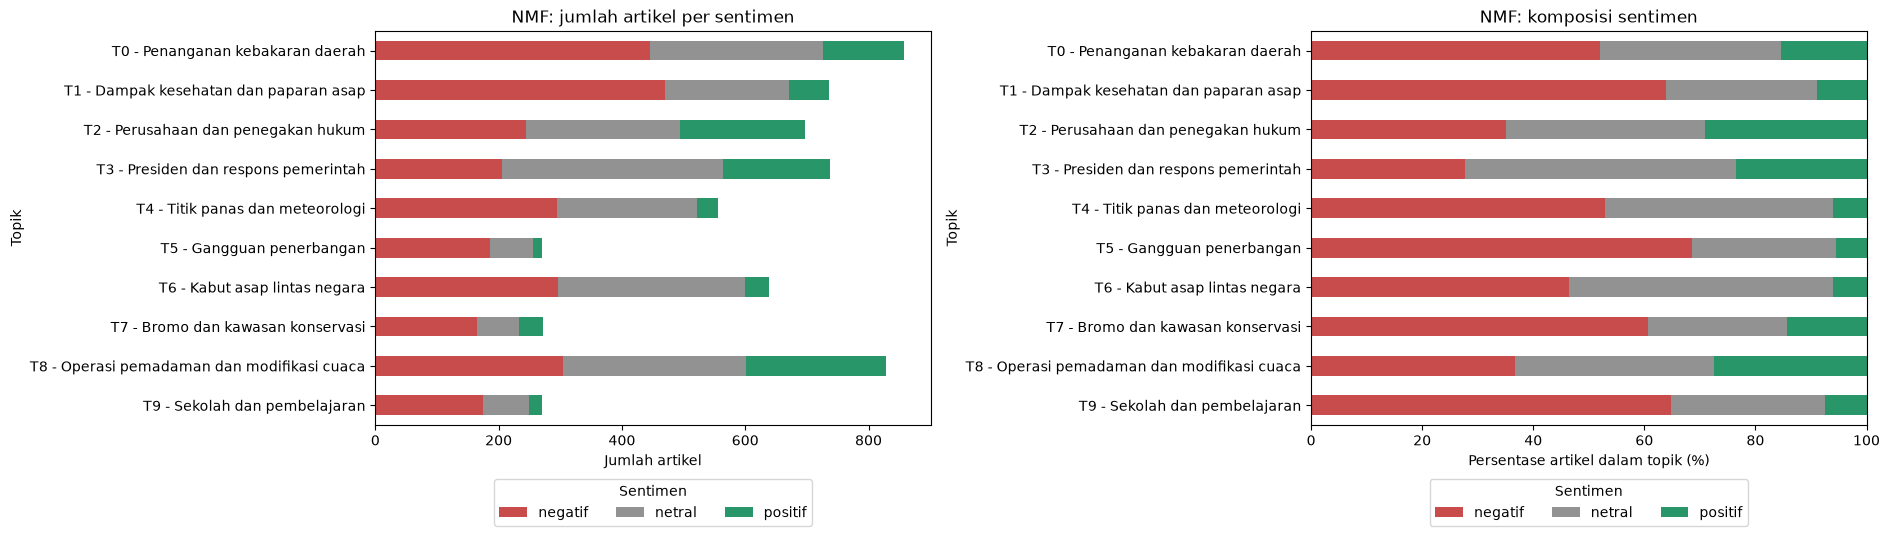

In [18]:
#setup pewarnaan untuk kemudahan interpretasi grafik
warna_sentimen = ['#c94c4c', '#929292', '#29966a']
label_topik = ringkasan_sentimen_nmf['Isu'].tolist()
jumlah_grafik = jumlah_sentimen_nmf.copy()
persen_grafik = persen_sentimen_nmf.copy()
jumlah_grafik.index = label_topik
persen_grafik.index = label_topik

fig, axes = plt.subplots(1, 2, figsize=(19, max(5, 0.55 * len(label_topik))))
jumlah_grafik.plot.barh(stacked=True, ax=axes[0], color=warna_sentimen)
persen_grafik.plot.barh(stacked=True, ax=axes[1], color=warna_sentimen)
axes[0].set(title='NMF: jumlah artikel per sentimen', xlabel='Jumlah artikel', ylabel='Topik')
axes[1].set(
    title='NMF: komposisi sentimen',
    xlabel='Persentase artikel dalam topik (%)',
    ylabel='Topik',
)
axes[1].set_xlim(0, 100)
for ax in axes:
    ax.invert_yaxis()
    ax.legend(title='Sentimen', loc='upper center', bbox_to_anchor=(0.5, -0.12), ncol=3)
plt.tight_layout()
plt.show()

Grafik jumlah artikel memperlihatkan ukuran topik beserta jumlah setiap sentimen. Sedangkan grafik persentase membandingkan komposisi pada skala yang sama meskipun ukuran topiknya berbeda.

### 3.5. Topik Terbesar dan Komposisi Sentimennya

Tabel berikut merangkum tiga topik dengan artikel terbanyak, persentasenya terhadap seluruh artikel yang dimodelkan, dan komposisi sentimen dalam masing-masing topik. Kedua persentase memakai penyebut berbeda: kolom **Persentase (%)** memakai seluruh 5.865 artikel, sedangkan persentase sentimen memakai total artikel pada topik terkait.

In [19]:
topik_utama = ringkasan_topik_nmf.head(3).copy()
kolom_sentimen = [
    'negatif (%)', 'netral (%)', 'positif (%)',
    'Sentimen terbanyak', 'Porsi terbesar (%)',
]
topik_utama = topik_utama.join(ringkasan_sentimen_nmf[kolom_sentimen])
print('Tiga topik terbesar dan komposisi label sentimennya')
display(topik_utama)

Tiga topik terbesar dan komposisi label sentimennya


,Topik,Jumlah artikel,Persentase (%),negatif (%),netral (%),positif (%),Sentimen terbanyak,Porsi terbesar (%)
Kode topik NMF,,,,,,,,
0,T0 - Penanganan kebakaran daerah,858,14.63,51.98,32.63,15.38,negatif,51.98
8,T8 - Operasi pemadaman dan modifikasi cuaca,828,14.12,36.71,35.87,27.42,negatif,36.71
3,T3 - Presiden dan respons pemerintah,738,12.58,27.78,48.64,23.58,netral,48.64


**T0 - Penanganan kebakaran daerah** terdiri dari **858 artikel**. Label terbanyak adalah **negatif (51,98%)** dari artikel pada topik tersebut.

**T8 - Operasi pemadaman dan modifikasi cuaca** terdiri dari **828 artikel**. Label terbanyak adalah **negatif (36,71%)** dari artikel pada topik tersebut.

**T3 - Presiden dan respons pemerintah** terdiri dari **738 artikel**. Label terbanyak adalah **netral (48,64%)** dari artikel pada topik tersebut.

Perbedaan ini menggambarkan komposisi label pemberitaan di antara topik terbesar. Namun porsi label terbanyak belum tentu merupakan mayoritas di atas 50%.

## 4. Penelusuran Penyebutan Sawit

Penelusuran ini menanggapi rasa ingin tahu tentang kaitan sawit dan karhutla melalui penyebutan dalam artikel berita. 

,Jumlah artikel
Menyebut pada judul,73
Menyebut pada isi,378
"Judul atau isi, tanpa hitung ganda",381


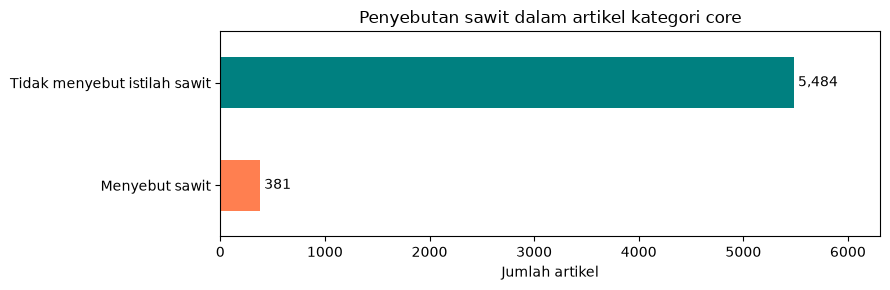

In [20]:
#cek kata sawit dari judul dan konten
pola_sawit = r'\bsawit\b|\bpalm oil\b'
judul_sawit = berita['title_clean'].str.contains(pola_sawit, case=False, regex=True)
isi_sawit = berita['content_clean'].str.contains(pola_sawit, case=False, regex=True)
berita['menyebut_sawit'] = judul_sawit | isi_sawit
artikel_sawit = berita[berita['menyebut_sawit']].copy()

ringkasan_sawit = pd.Series({
    'Menyebut pada judul': int(judul_sawit.sum()),
    'Menyebut pada isi': int(isi_sawit.sum()),
    'Judul atau isi, tanpa hitung ganda': len(artikel_sawit),
})
display(ringkasan_sawit.to_frame('Jumlah artikel'))

jumlah_sawit = pd.Series({
    'Menyebut sawit': len(artikel_sawit),
    'Tidak menyebut istilah sawit': len(berita) - len(artikel_sawit),
})
fig, ax = plt.subplots(figsize=(9, 3))
jumlah_sawit.plot.barh(ax=ax, color=['coral', 'teal'])
ax.set(title='Penyebutan sawit dalam artikel kategori core', xlabel='Jumlah artikel', ylabel='')
for posisi, jumlah in enumerate(jumlah_sawit):
    ax.text(jumlah, posisi, f' {jumlah:,}', va='center')
ax.margins(x=0.15)
plt.tight_layout()
plt.show()

Hanya **381 dari 5.865 artikel (6,5%)** menyebut kata sawit, terdiri dari **73 artikel pada judul** dan **378 artikel pada isi**. 

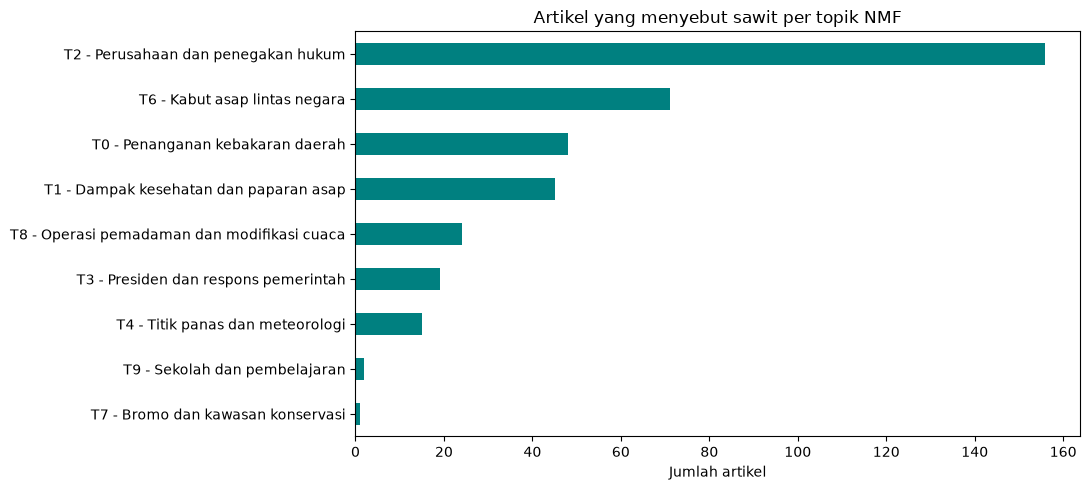

,Artikel yang menyebut sawit,Seluruh artikel topik,Persen dalam topik
isu,,,
T2 - Perusahaan dan penegakan hukum,156,697,22.4
T6 - Kabut asap lintas negara,71,639,11.1
T0 - Penanganan kebakaran daerah,48,858,5.6
T1 - Dampak kesehatan dan paparan asap,45,736,6.1
T8 - Operasi pemadaman dan modifikasi cuaca,24,828,2.9
T3 - Presiden dan respons pemerintah,19,738,2.6
T4 - Titik panas dan meteorologi,15,556,2.7
T9 - Sekolah dan pembelajaran,2,270,0.7
T7 - Bromo dan kawasan konservasi,1,272,0.4


In [21]:
#sebaran kata sawit pada topik
sebaran_sawit_nmf = artikel_sawit['isu'].value_counts()
fig, ax = plt.subplots(figsize=(11, 5))
sebaran_sawit_nmf.sort_values().plot.barh(ax=ax, color='teal')
ax.set(title='Artikel yang menyebut sawit per topik NMF', xlabel='Jumlah artikel', ylabel='')
plt.tight_layout()
plt.show()

rincian_nmf = pd.DataFrame({'Artikel yang menyebut sawit': sebaran_sawit_nmf})
rincian_nmf['Seluruh artikel topik'] = ukuran_isu
rincian_nmf['Persen dalam topik'] = (
    100 * rincian_nmf['Artikel yang menyebut sawit'] / rincian_nmf['Seluruh artikel topik']
).round(1)
display(rincian_nmf)

Penyebutan sawit paling banyak terdapat pada **T2 - Perusahaan dan penegakan hukum (156 artikel)**, **T6 - Kabut asap lintas negara (71 artikel)**, dan **T0 - Penanganan kebakaran daerah (48 artikel)**. 

### Konteks Sawit dalam Contoh Artikel

Tabel berikut menampilkan contoh artikel yang memuat konteks sawit dengan informasi identitas, judul, media, potongan isi, dan tautan sumber. Potongan teks memperlihatkan konteks sekitar istilah, hubungan sebab akibat tetap memerlukan pemeriksaan isi artikel secara utuh.

In [22]:
prioritas = artikel_sawit.drop_duplicates('source_domain')
calon_contoh = pd.concat([prioritas, artikel_sawit]).drop_duplicates('doc_id')
contoh_sawit = calon_contoh.head(4).copy()
assert (
    len(contoh_sawit) == min(4, len(artikel_sawit))
), 'Jumlah contoh tidak sesuai dengan artikel tersedia.'
pola_potongan = r'(?is)(.{0,100}(?:\bsawit\b|\bpalm oil\b).{0,220})'
contoh_sawit['potongan_isi'] = contoh_sawit['content_clean'].str.extract(
    pola_potongan, expand=False,
)
contoh_sawit['potongan_isi'] = contoh_sawit['potongan_isi'].fillna(
    'Istilah hanya ditemukan pada judul; periksa isi lengkap.',
)

kolom_sawit = ['doc_id', 'title_clean', 'source_domain', 'potongan_isi', 'link']
with pd.option_context('display.max_colwidth', None):
    display(contoh_sawit[kolom_sawit])

,doc_id,title_clean,source_domain,potongan_isi,link
8,D00160,"BMKG Ingatkan Lagi soal Kemarau, Karhutla dan Kekeringan",mongabay.co.id,"tan 2.412 titik. Dia bilang, mengubah fungsi gambut menjadi lahan monokultur skala luas, baik untuk sawit, padi, maupun tebu, memerlukan pengeringan lahan melalui pembuatan kanal-kanal air. Padahal, regulasi di Indonesia membatasi bahwa gambut yang boleh dibudidayakan maksimal memiliki ketebalan tiga meter. “Itu (tiga meter",https://mongabay.co.id/2026/06/13/bmkg-ingatkan-lagi-soal-kemarau-karhutla-dan-kekeringan/
50,D00440,"Puncak Kemarau Belum Datang, 67 Ribu Ha Lahan Sudah Terpanggang",betahita.id,"paruh area terbakar (52,23 persen atau 35 ribu hektar) tumpang tindih dengan izin dan konsesi. Izin sawit mendominasi dengan 19 ribu hektar area terbakar, artinya praktik pengelolaan lahan di wilayah perusahaan masih menjadi faktor utama kerentanan. Lonjakan AIT di izin sawit naik hampir dua kali lipat dari Januari ke Maret",https://www.betahita.id/berita/12009/puncak-kemarau-belum-datang-67-ribu-ha-lahan-sudah-terpanggang
57,D00453,"Malaysia Siap Bawa Isu Karhutla ke ASEAN, Begini Respons Tegas Kemlu",cnbcindonesia.com,""" katanya, Kamis (22/10/2026).\nBaca:\nWamentan Perintah Lahan Bekas Karhutla di Kalteng Tak Ditanami Sawit\nTerkait manuver Malaysia yang ingin membawa masalah ini ke meja regional, Vahd mengingatkan bahwa mekanisme ASEAN yang khusus membahas isu ini sebenarnya sudah terbentuk dan berjalan dengan baik. Bantuan dari negara mit",https://www.cnbcindonesia.com/news/20261022172128-4-778673/malaysia-siap-bawa-isu-karhutla-ke-asean-begini-respons-tegas-kemlu
75,D00684,"Kronologi Orang Utan Mati Usai Hirup Asap Karhutla di Kalimantan, Sempat Pingsan dan Dievakuasi Petugas",grid.id,"redar di sosial media, tampak petugas berupaya mengevakuasi seekor orangutan dari tengah perkebunan sawit milik warga di Desa Laman Satong, Kecamatan Matan Hilir Utara, Kabupaten Ketapang, Kalimantan Barat, Minggu (30/8/2026). Kronologi Orang Utan Mati Usai Hirup Asap Karhutla di Kalimantan Saat ditemukan, Orang Utan malang",https://www.grid.id/read/044409912/kronologi-orang-utan-mati-usai-hirup-asap-karhutla-di-kalimantan-sempat-pingsan-dan-dievakuasi-petugas


Keempat contoh memperlihatkan setidaknya tiga konteks substantif: 
- pengelolaan gambut
- kawasan konsesi, dan 
- lokasi terdampaknya satwa. 

Konteks tersebut dapat membantu menjelaskan bagaimana sawit muncul dalam pemberitaan karhutla.

## 5. Kesimpulan dan Batasan

### Kesimpulan

Analisis menggunakan **5.865 artikel core** dari **9.161 artikel yang sudah dibersihkan**. NMF membagi artikel menjadi sepuluh topik dengan tiga terbesar adalah **T0 Penanganan kebakaran daerah (858)**, **T8 Operasi pemadaman dan modifikasi cuaca (828)**, dan **T3 Presiden dan respons pemerintah (738)**. Ketiganya mencakup **41,33%** artikel, sehingga pemberitaan didominasi urusan penanganan dan respons pemerintah.

Adapun berdasarkan klasifikasi sentimen, sentimen **negatif** mempunyai proporsi paling banyak: **2.787 artikel (47,52%)**, diikuti **netral 2.132 (36,35%)** dan **positif 946 (16,13%)**. Per topik, T0 condong negatif (51,98%), T8 juga negatif (36,71%), dan T3 condong netral (48,64%). Pada T8 dan T3, label terbanyak belum mencapai mayoritas.

Kemudian berkaitan dengan sawit, kata sawit disebut dalam **381 artikel (6,5%)**, dengan paling banyak muncul di **T2 Perusahaan dan penegakan hukum (156)**, **T6 Kabut asap lintas negara (71)**, dan **T0 Penanganan kebakaran daerah (48)**. Hal ini berarti sawit muncul di beberapa kelompok berita, namun nama topik belum menunjukkan konteks atau siapa yang dianggap bertanggung jawab.

### Batasan

- Jumlah artikel menunjukkan seberapa sering sesuatu diberitakan, dan tidak menggambarkan seberapa sering atau seberapa parah kebakaran terjadi.
- Nama topik merupakan tafsir dari kata utama dan contoh artikel.
- Sentimen berasal dari aturan buatan yang memprioritaskan judul, kemudian baru dicek kedalam isi konten.
- Pencarian sawit hanya memakai kata sawit dan frasa palm oil.
- Data tidak memuat media sosial. sehingga kesimpulan hanya berlaku dalam konteks artikel berita yang dianalisis.